In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import ast

In [20]:
# Read in woke
wokeGames = pd.read_csv("Data/wokeGames.csv")
wokeGames.drop(columns=["Unnamed: 0"], inplace=True)
print(wokeGames.head())

         0
0   780290
1  1040390
2  2322440
3   296970
4  2027530


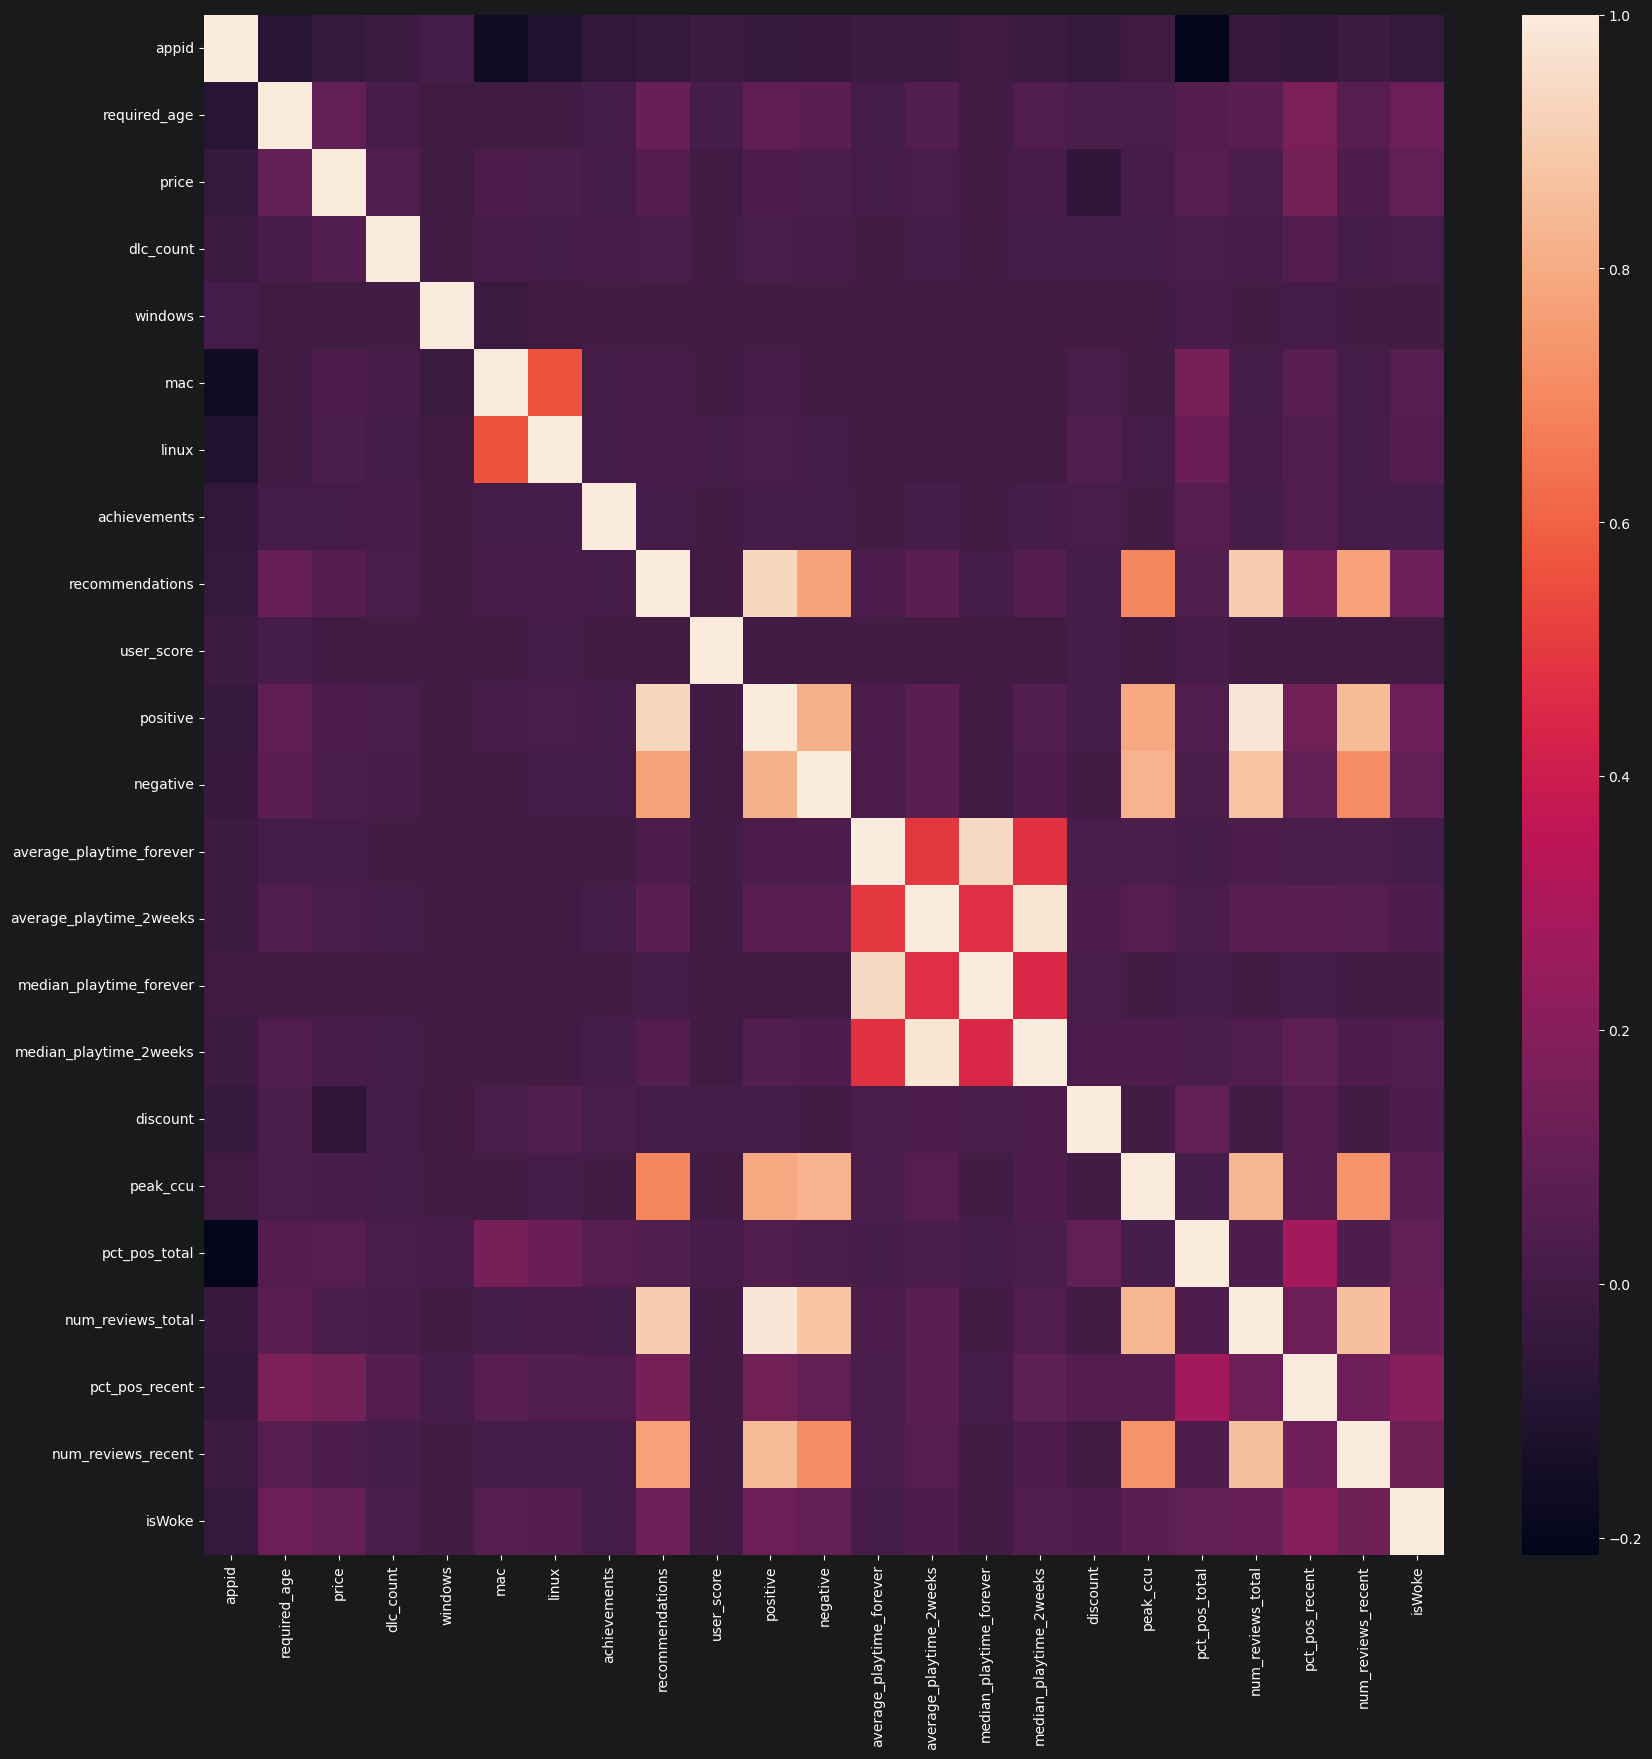

In [21]:
# Read in file
steam = pd.read_csv("Data/games_march2025_cleaned.csv")
steam = steam.drop(columns=["about_the_game", "release_date", "short_description",
                            "detailed_description", "support_url", "support_email",
                            "website", "reviews", "metacritic_score", "metacritic_url",
                            "notes", "score_rank", "header_image", "packages", "developers", "publishers",
                            "screenshots", "movies", "estimated_owners", "name", "tags"]) #NEED TO WRITE SOMETHING FOR TAGS
steam["isWoke"] = steam["appid"].isin(wokeGames["0"])

steam_temp = steam.drop(columns=["supported_languages", "full_audio_languages", "categories", "genres"])
correlation_matrix = steam_temp.corr()
plt.figure(figsize=(20,20))
sns.heatmap(correlation_matrix, fmt="g")
plt.show()


In [22]:
def dummyVariable(name_of_feature):
    global steam
    steam["temp"] = steam[name_of_feature].apply(ast.literal_eval)
    exploded_languages = steam["temp"].explode()
    # turn many values of the same langauge from the explosion into "max", whether it supports that language or not
    dummies_languages = pd.get_dummies(exploded_languages).groupby(level=0).max()
    dummies_languages.columns += "_" + name_of_feature
    #print(dummies_languages.head())
    steam = pd.concat([steam, dummies_languages], axis=1)
    steam.drop(columns=["temp", name_of_feature], inplace=True)

dummyVariable("supported_languages")
dummyVariable("full_audio_languages")
dummyVariable("categories")
dummyVariable("genres")


In [23]:
print(steam.shape)
print(steam.head())
print(steam.info())
print(steam.iloc[50000].info())
steam.to_csv("test.csv")

(89618, 309)
    appid  required_age  price  dlc_count  windows    mac  linux  \
0     730             0   0.00          1     True  False   True   
1  578080             0   0.00          0     True  False  False   
2     570             0   0.00          2     True   True   True   
3  271590            17   0.00          0     True  False  False   
4  359550            17   3.99          9     True  False  False   

   achievements  recommendations  user_score  ...  Short_genres  \
0             1          4401572           0  ...         False   
1            37          1732007           0  ...         False   
2             0            14337           0  ...         False   
3            77          1803063           0  ...         False   
4             0          1165929           0  ...         False   

   Simulation_genres  Software Training_genres  Sports_genres  \
0              False                     False          False   
1              False                     Fals

In [26]:
correlation_matrix = steam.corr()
correlation_matrix.to_csv("correlation.csv")
#print(correlation_matrix)
#plt.figure(figsize=(20,20))
#sns.heatmap(correlation_matrix, fmt="g")
#plt.show()

                            appid  required_age     price  dlc_count  \
appid                    1.000000     -0.083292 -0.043427  -0.024001   
required_age            -0.083292      1.000000  0.089948   0.016312   
price                   -0.043427      0.089948  1.000000   0.039387   
dlc_count               -0.024001      0.016312  0.039387   1.000000   
windows                  0.009077     -0.010425 -0.005652   0.000710   
...                           ...           ...       ...        ...   
Tutorial_genres         -0.000811     -0.000355 -0.001584  -0.000130   
Utilities_genres        -0.015740     -0.010450  0.028106   0.001145   
Video Production_genres -0.011784     -0.006010  0.058619   0.001875   
Violent_genres          -0.074120      0.040119 -0.009873  -0.002059   
Web Publishing_genres   -0.015068     -0.003539  0.031298   0.056979   

                          windows       mac     linux  achievements  \
appid                    0.009077 -0.160776 -0.109191     -0.056